In [ ]:
import pandas as pd
import numpy as np
from google.colab import drive
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/MonografiaI/Artigo/dataset_mensagens_e_codigos_ROTULADO.csv'
df_rotulado = pd.read_csv(file_path)

print(df_rotulado.shape)
df_rotulado.head()


Mounted at /content/drive
(800, 7)


,id,sourceAbs,sourceText,mensagem_erro,rotulo,Unnamed: 5,Unnamed: 6
0,4,# include < stdio . h >\n# include < stdlib . ...,#include <stdio.h>\n#include <stdlib.h>\nint n...,clang: error: linker command failed with exit ...,C4,NaN,NaN
1,33,# include < stdio . h >\n# include < stdlib . ...,#include <stdio.h>\n#include <stdlib.h>\n\nstr...,clang: error: linker command failed with exit ...,C4,NaN,NaN
2,67,# include < stdio . h >\n# include < stdlib . ...,#include <stdio.h>\n#include <stdlib.h>\n\n\ni...,clang: error: linker command failed with exit ...,C4,NaN,NaN
3,78,"# include < stdio . h >\n\nint TypeKind.INT , ...","#include <stdio.h>\n\nint N, T, array[30]; // ...",clang: error: linker command failed with exit ...,C4,NaN,NaN
4,92,# include < stdio . h >\n\nint TypeKind.FUNCTI...,"#include <stdio.h>\n \nint maximum( int a[],in...",clang: error: linker command failed with exit ...,C4,NaN,NaN


In [ ]:
df_rotulado["texto_combinado"] = (
    df_rotulado["mensagem_erro"].fillna("") + " " +
    df_rotulado["sourceText"].fillna("")
)


In [ ]:
X = df_rotulado["texto_combinado"]
y = df_rotulado["rotulo"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
modelo = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

modelo.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
y_pred = modelo.predict(X_test_tfidf)

print("Relatório de Classificação:")
print(classification_report(y_test, y_pred))



Relatório de Classificação:
              precision    recall  f1-score   support

          C1       0.85      0.81      0.83        36
          C2       0.77      0.69      0.73        59
          C3       0.53      0.68      0.59        28
          C4       0.64      0.52      0.57        27
          C5       0.20      0.40      0.27         5
          C6       0.33      0.50      0.40         2
          C7       0.00      0.00      0.00         2
         OUT       0.00      0.00      0.00         1

    accuracy                           0.66       160
   macro avg       0.42      0.45      0.42       160
weighted avg       0.69      0.66      0.67       160



Matriz de confusão (valores absolutos):
[[29  1  3  1  2  0  0  0]
 [ 3 41  8  4  1  1  0  1]
 [ 0  3 19  3  1  1  1  0]
 [ 1  5  5 14  2  0  0  0]
 [ 1  1  1  0  2  0  0  0]
 [ 0  1  0  0  0  1  0  0]
 [ 0  0  0  0  2  0  0  0]
 [ 0  1  0  0  0  0  0  0]]


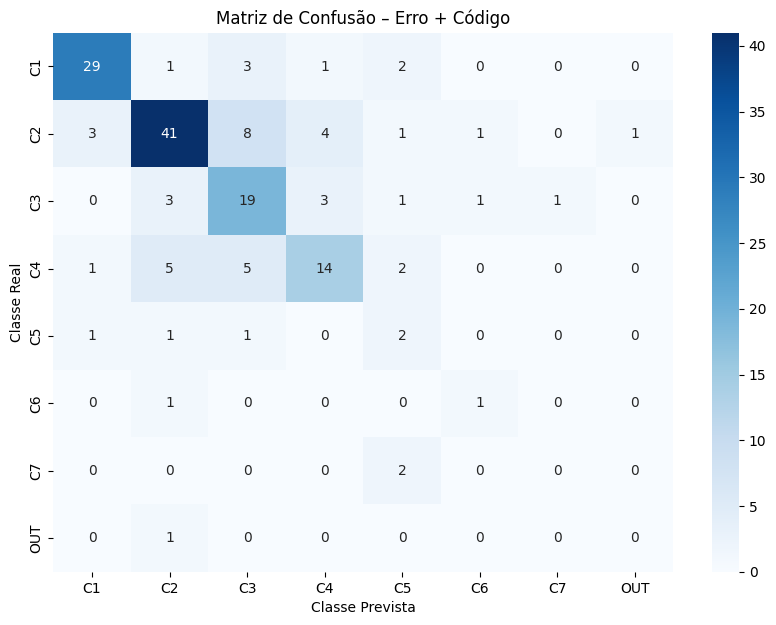

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=modelo.classes_
)

print("Matriz de confusão (valores absolutos):")
print(cm)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=modelo.classes_,
    yticklabels=modelo.classes_
)
plt.xlabel('Classe Prevista')
plt.ylabel('Classe Real')
plt.title('Matriz de Confusão – Erro + Código')
plt.show()